# Session 6 · Hands-On Labs / Laboratorios prácticos
## Experimental Best Practices: Splits, Seeds & Statistical Rigor
## Buenas prácticas experimentales: particiones, semillas y rigor estadístico
**Doctoral Program in Deep Technologies · UNMSM · Dr. Loveleen Gaur**

Six short labs. Each one takes a claim from the slides and lets you **see it happen with your own eyes**.
No installation: open in Google Colab and press `Shift + Enter` on each cell.

> **ES:** Seis laboratorios cortos. Cada uno toma una afirmación de las diapositivas y te permite **verla ocurrir con tus propios ojos**. Sin instalación: ábrelo en Google Colab y presiona `Shift + Enter` en cada celda.

| Lab | English | Español | The trap it exposes / La trampa |
|---|---|---|---|
| 1 | The Seed Lottery | La lotería de la semilla | One run is luck / Una sola corrida es suerte |
| 2 | The Leak Detector | El detector de fugas | Test data sneaks into training / El test se filtra al entrenamiento |
| 3 | The Patient Twins | Los pacientes gemelos | Same person in train and test / La misma persona en train y test |
| 4 | The Peeking Simulator | El simulador de "espiar" | Stopping when you like the result / Parar cuando te gusta el resultado |
| 5 | Significant ≠ Important | Significativo ≠ importante | p-values without effect sizes / Valores p sin tamaño del efecto |
| 6 | The Fair Fight | La pelea justa | Comparing models the wrong way / Comparar modelos mal |

**How to use each lab / Cómo usar cada lab:**
1. 🤔 **Predict** first (write your guess in the cell). / **Predice** primero.
2. ▶️ **Run** the code. / **Ejecuta** el código.
3. 💡 **Explain** what surprised you to your neighbor. / **Explica** a tu compañero qué te sorprendió.

In [1]:
# Run me first / Ejecútame primero
import warnings; warnings.filterwarnings("ignore")   # hide convergence chatter / ocultar avisos
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (train_test_split, cross_val_score, StratifiedKFold,
                                     GroupKFold, KFold, RepeatedStratifiedKFold)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

NAVY, TEAL, AMBER, RED = "#0F2233", "#14897F", "#F2A33A", "#D9534F"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
print("Ready / Listo ✅")

Ready / Listo ✅


---
## Lab 1 · The Seed Lottery 🎲 / La lotería de la semilla
**Slide claim:** a single run is a coin toss.
**ES · Afirmación:** una sola corrida es un volado (cara o sello).

**The story.** Two PhD students train *the same* small neural network on *the same* breast-cancer dataset. The only difference is the **random seed**, the starting number for the computer's "dice". One writes "our model reaches 98%". The other writes "only 95%". Who is right? **Both, and neither.**

> **ES · La historia.** Dos doctorandos entrenan *la misma* red neuronal pequeña con *el mismo* conjunto de datos de cáncer de mama. La única diferencia es la **semilla aleatoria**, el número inicial de los "dados" de la computadora. Uno escribe "nuestro modelo llega a 98%". El otro, "solo 95%". ¿Quién tiene razón? **Ambos, y ninguno.**

🤔 **Predict / Predice:** across 20 seeds, how many percentage points between the best and worst run? / En 20 semillas, ¿cuántos puntos entre la mejor y la peor corrida?

`My guess / Mi apuesta: ____ points`

In [2]:
X, y = load_breast_cancer(return_X_y=True)  # 569 real patients / 569 pacientes reales

def lab1_runs(hidden_units):
    scores = []
    for seed in range(20):
        Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=seed, stratify=y)
        scaler = StandardScaler().fit(Xtr)
        model = MLPClassifier(hidden_layer_sizes=(hidden_units,), max_iter=300, random_state=seed)
        model.fit(scaler.transform(Xtr), ytr)
        scores.append(model.score(scaler.transform(Xte), yte) * 100)
    return np.array(scores)

scores_16 = lab1_runs(16)
accuracies = lab1_runs(64)  # requested change / cambio solicitado
for units, scores in [(16, scores_16), (64, accuracies)]:
    print(f"Network {units:>2} neurons / neuronas: mean={scores.mean():.1f}%, SD={scores.std(ddof=1):.2f}, spread={np.ptp(scores):.1f} points")
print("Conclusion / Conclusión:", "the spread shrank / el rango se redujo" if np.ptp(accuracies) < np.ptp(scores_16) else "the spread did not shrink / el rango no se redujo")


Network 16 neurons / neuronas: mean=97.2%, SD=1.01, spread=3.5 points
Network 64 neurons / neuronas: mean=97.1%, SD=0.92, spread=3.5 points
Conclusion / Conclusión: the spread did not shrink / el rango no se redujo


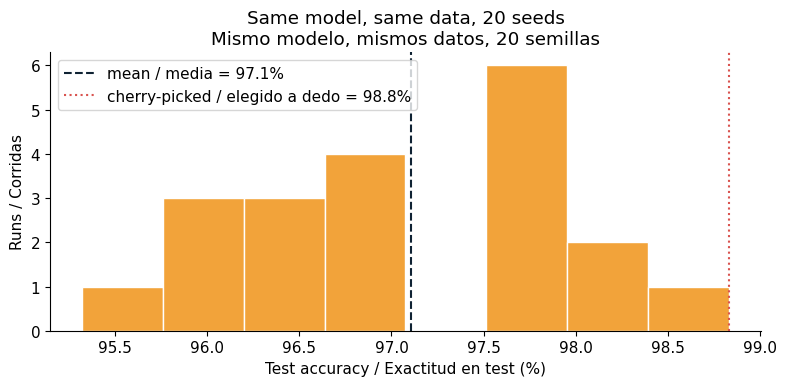

In [3]:
plt.figure(figsize=(8, 4))
plt.hist(accuracies, bins=8, color=AMBER, edgecolor="white")
plt.axvline(accuracies.mean(), color=NAVY, linestyle="--", label=f"mean / media = {accuracies.mean():.1f}%")
plt.axvline(accuracies.max(), color=RED, linestyle=":", label=f"cherry-picked / elegido a dedo = {accuracies.max():.1f}%")
plt.title("Same model, same data, 20 seeds\nMismo modelo, mismos datos, 20 semillas")
plt.xlabel("Test accuracy / Exactitud en test (%)"); plt.ylabel("Runs / Corridas")
plt.legend(); plt.tight_layout(); plt.show()

### 1b · Where does the luck come from? / ¿De dónde viene la suerte?
There are **two dice**: (1) which patients land in the test set (the *split*), and (2) where the network starts learning (the *initialization*). Let's roll each one separately.

> **ES:** Hay **dos dados**: (1) qué pacientes caen en el conjunto de test (la *partición*) y (2) desde dónde empieza a aprender la red (la *inicialización*). Tiremos cada uno por separado.

In [4]:
def run(split_seed, init_seed, hidden_units=64):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=split_seed, stratify=y)
    sc = StandardScaler().fit(Xtr)
    m = MLPClassifier(hidden_layer_sizes=(hidden_units,), max_iter=300, random_state=init_seed)
    return m.fit(sc.transform(Xtr), ytr).score(sc.transform(Xte), yte) * 100

only_split = np.array([run(s, 0) for s in range(20)])
only_init  = np.array([run(0, s) for s in range(20)])
print(f"Only the SPLIT changes / Solo cambia la PARTICIÓN : SD = {only_split.std(ddof=1):.2f} pts, range = {np.ptp(only_split):.1f}")
print(f"Only the INIT changes / Solo cambia la INICIALIZACIÓN: SD = {only_init.std(ddof=1):.2f} pts, range = {np.ptp(only_init):.1f}")


Only the SPLIT changes / Solo cambia la PARTICIÓN : SD = 0.99 pts, range = 3.5
Only the INIT changes / Solo cambia la INICIALIZACIÓN: SD = 0.13 pts, range = 0.6


### ✅ Question 1 · Lab 1
**Question:** Change to `hidden_layer_sizes=(64,)`. Does a bigger network shrink the spread?

**Answer: No. A bigger network does not shrink the spread.**

| Network | Mean | SD | Spread (best − worst) |
|---|---|---|---|
| 16 neurons (original) | 97.2% | 1.01 | 3.5 pts |
| 64 neurons (requested change) | 97.1% | 0.92 | 3.5 pts |

Quadrupling the hidden layer barely moves the SD (1.01 → 0.92) and leaves the best-to-worst spread unchanged at 3.5 points. Lab 1b, just above, shows why: the variation comes mainly from the **split** (SD 0.99 when only the split changes) rather than from the **initialization** (SD 0.13 when only the starting weights change). A bigger network can only act on the initialization part.

With 171 test patients, one patient is worth 0.58 points, so a 3.5-point spread means about 6 patients changing sides. That spread belongs to the test sample, not to the model. Repeated cross-validation or a larger test set reduces it; a bigger network does not.

💡 **What you should see / Qué deberías ver:** accuracy is a **band, not a number**. On small datasets (like most management and health datasets), *which cases land in the test set* usually matters more than the network's starting point.

**The honest move:** report **mean ± standard deviation over many seeds**, and say which randomness you varied.

> **ES:** la exactitud es una **franja, no un número**. En datos pequeños (como la mayoría de datos de gestión y salud), *qué casos caen en el test* suele importar más que el punto de partida de la red. **Lo honesto:** reportar **media ± desviación estándar sobre muchas semillas** e indicar qué aleatoriedad variaste.

---
## Lab 2 · The Leak Detector 💧 / El detector de fugas
**Slide claim:** if information from the test set touches training, your score is fiction.
**ES · Afirmación:** si información del test toca el entrenamiento, tu resultado es ficción.

### 2a · The small leak: scaling before splitting / La fuga pequeña: escalar antes de partir

In [5]:
def evaluate(leaky, seed=0):
    if leaky:
        # WRONG / INCORRECTO: scale the WHOLE dataset first, the scaler "sees" the test set
        Xs = StandardScaler().fit_transform(X)
        Xtr, Xte, ytr, yte = train_test_split(Xs, y, test_size=0.3, random_state=seed, stratify=y)
    else:
        # RIGHT / CORRECTO: split first, then learn scaling from TRAIN only
        Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=seed, stratify=y)
        sc = StandardScaler().fit(Xtr); Xtr, Xte = sc.transform(Xtr), sc.transform(Xte)
    return LogisticRegression(max_iter=2000).fit(Xtr, ytr).score(Xte, yte) * 100

leaky_a = np.mean([evaluate(True, s) for s in range(30)])
clean_a = np.mean([evaluate(False, s) for s in range(30)])
print(f"Leaky / Con fuga : {leaky_a:.2f}%")
print(f"Clean / Limpio   : {clean_a:.2f}%")
print(f"Difference / Diferencia: {leaky_a-clean_a:+.2f} points")

Leaky / Con fuga : 97.60%
Clean / Limpio   : 97.56%
Difference / Diferencia: +0.04 points


**Honest note / Nota honesta:** with simple scaling on a clean dataset, the gap is **tiny**. That is exactly why this leak survives peer review: it *looks* harmless. Now watch a leak that is **not** harmless.

> **ES:** con un escalado simple en datos limpios, la diferencia es **mínima**. Por eso esta fuga sobrevive a la revisión por pares: *parece* inofensiva. Ahora mira una fuga que **no** es inofensiva.

### 2b · The big leak: "Predicting the unpredictable" / La fuga grande: "Predecir lo impredecible"
We create **pure noise**: 100 "customers", 5,000 random features, and a **coin-flip** label. There is *nothing* to learn. An honest model must score about **50%**.

The leaky researcher first picks the *k* features "most related to the label" using **all** the data, then runs cross-validation (original setting `k=20`; Question 2 also tries `k=5` and `k=100`).

> **ES:** Creamos **ruido puro**: 100 "clientes", 5 000 variables aleatorias y una etiqueta tirada **a cara o sello**. No hay *nada* que aprender. Un modelo honesto debe dar cerca de **50%**. El investigador con fuga primero elige las *k* variables "más relacionadas con la etiqueta" usando **todos** los datos y luego hace validación cruzada.

🤔 **Predict / Predice:** what accuracy will the leaky researcher report on pure noise? / ¿Qué exactitud reportará sobre ruido puro?

In [6]:
rng = np.random.default_rng(42)
X_noise = rng.normal(size=(100, 5000))
y_noise = rng.integers(0, 2, size=100)
cv = StratifiedKFold(5, shuffle=True, random_state=0)

for k in (5, 20, 100):
    X_sel = SelectKBest(f_classif, k=k).fit_transform(X_noise, y_noise)
    leaky = cross_val_score(LogisticRegression(max_iter=1000), X_sel, y_noise, cv=cv).mean() * 100
    pipe = make_pipeline(SelectKBest(f_classif, k=k), LogisticRegression(max_iter=1000))
    clean = cross_val_score(pipe, X_noise, y_noise, cv=cv).mean() * 100
    print(f"k={k:>3}: leaky / con fuga={leaky:.1f}% | clean / limpio={clean:.1f}% | gap / diferencia={leaky-clean:+.1f} pp")


k=  5: leaky / con fuga=78.0% | clean / limpio=49.0% | gap / diferencia=+29.0 pp
k= 20: leaky / con fuga=90.0% | clean / limpio=45.0% | gap / diferencia=+45.0 pp
k=100: leaky / con fuga=99.0% | clean / limpio=48.0% | gap / diferencia=+51.0 pp


### ✅ Question 2 · Lab 2b
**Question:** Change `k=20` to `k=5`, then to `k=100`. When is the leak worst?

**Answer: The leak is worst with `k=100`.**

| k | Leaky (selection on all data) | Clean (selection inside the Pipeline) | Gap |
|---|---|---|---|
| 5 | 78.0% | 49.0% | +29.0 pp |
| 20 (original) | 90.0% | 45.0% | +45.0 pp |
| 100 | **99.0%** | 48.0% | **+51.0 pp** |

The clean pipeline stays near 50% (chance) for every k, as it should on pure noise. The leaky version grows with k. Among 5,000 random features, some correlate with the coin-flip label by chance. Selecting them on **all** 100 rows lets the test labels choose the features, so the model inherits those chance correlations. The more features chosen this way, the more spurious signal it inherits: with 100 features for 100 rows, the leaky setup reaches 99% on data that contains no signal. Even `k=5` adds 29 points of fiction.

💡 **What you should see:** the leaky setup reports a high, publishable-looking accuracy **on data with no signal at all**. The fix is one line: put every data-dependent step (scaling, imputing, selecting, oversampling with SMOTE) **inside a `Pipeline`**, so it is re-learned inside each training fold.

This is the mistake behind many of the **294 leaky papers in 17 fields** found by Kapoor & Narayanan (2023, *Patterns*).

> **ES:** la versión con fuga reporta una exactitud alta y "publicable" **sobre datos sin ninguna señal**. La solución es una línea: poner todo paso que depende de los datos (escalar, imputar, seleccionar, sobremuestrear con SMOTE) **dentro de un `Pipeline`**, para que se reaprenda en cada pliegue de entrenamiento. Es el error detrás de muchos de los **294 artículos con fuga en 17 campos** (Kapoor y Narayanan, 2023).

---
## Lab 3 · The Patient Twins 👯 / Los pacientes gemelos
**Slide claim:** if the same person appears in training *and* test, the model memorizes **people**, not **disease**.
**ES · Afirmación:** si la misma persona aparece en entrenamiento *y* test, el modelo memoriza **personas**, no **enfermedades**.

**The story.** A hospital gives you 10 scans per patient for 80 patients. Each patient's scans share a personal "fingerprint" (body shape, scanner, positioning). The real disease signal is **weak**. You split the *scans* at random...

> **ES · La historia.** Un hospital te da 10 imágenes por paciente de 80 pacientes. Las imágenes de cada paciente comparten una "huella" personal (contextura, escáner, posición). La señal real de la enfermedad es **débil**. Tú partes las *imágenes* al azar...

The same trap appears in business: several transactions per customer, several visits per store, several quarters per firm.
> **ES:** La misma trampa aparece en negocios: varias transacciones por cliente, varias visitas por tienda, varios trimestres por empresa.

In [7]:
def lab3_scores(strength):
    rng = np.random.default_rng(7)
    n_patients, scans_each, n_feat = 80, 10, 30
    diagnosis = rng.integers(0, 2, n_patients)
    fingerprint = rng.normal(0, strength, size=(n_patients, n_feat))
    disease_dir = rng.normal(0, 1, n_feat); disease_dir /= np.linalg.norm(disease_dir)
    Xp, yp, groups = [], [], []
    for p in range(n_patients):
        for _ in range(scans_each):
            scan = fingerprint[p] + 0.6 * diagnosis[p] * disease_dir + rng.normal(0, 1, n_feat)
            Xp.append(scan); yp.append(diagnosis[p]); groups.append(p)
    Xp, yp, groups = np.array(Xp), np.array(yp), np.array(groups)
    rf = RandomForestClassifier(n_estimators=200, random_state=0)
    by_scan = cross_val_score(rf, Xp, yp, cv=KFold(5, shuffle=True, random_state=0)).mean() * 100
    by_patient = cross_val_score(rf, Xp, yp, cv=GroupKFold(5), groups=groups).mean() * 100
    return by_scan, by_patient

old_scan, old_patient = lab3_scores(3.0)   # original setting / valor original
by_scan, by_patient = lab3_scores(0.5)     # requested change / cambio solicitado
for label, s, p in [("3.0", old_scan, old_patient), ("0.5", by_scan, by_patient)]:
    s, p = round(s, 1), round(p, 1)   # round first so the gap matches the printed scores
    print(f"Fingerprint {label} / Huella {label}: by scan={s:.1f}%, by patient={p:.1f}%, gap={s-p:+.1f} pp")


Fingerprint 3.0 / Huella 3.0: by scan=99.2%, by patient=54.3%, gap=+44.9 pp
Fingerprint 0.5 / Huella 0.5: by scan=56.2%, by patient=48.8%, gap=+7.4 pp


### ✅ Question 3 · Lab 3
**Question:** Lower the fingerprint strength from `3.0` to `0.5`. What happens to the gap, and why?

**Answer: The gap collapses from +44.9 to +7.4 points, because a weak fingerprint makes patients hard to recognize.**

| Fingerprint strength | Split by scan (`KFold`) | Split by patient (`GroupKFold`) | Gap |
|---|---|---|---|
| 3.0 (original) | 99.2% | 54.3% | +44.9 pp |
| 0.5 (requested change) | 56.2% | 48.8% | +7.4 pp |

**Why:** the inflated by-scan score never came from the disease; it came from **recognizing the patient**. With strength 3.0, the fingerprint is three times larger than the per-scan noise (SD 1), so each patient's scans form a tight cluster. When sibling scans sit in the training folds, the forest identifies the person and copies their label. With strength 0.5, the fingerprint is weaker than the noise, identity is hard to memorize, and the shortcut almost disappears.

The patient-level score stays near chance (about 49–54%) in both cases because the true disease signal is weak. The remaining +7.4 points are still leakage, so `GroupKFold` remains necessary whenever one person contributes several rows.

💡 **What you should see:** splitting by scan looks brilliant; splitting by patient reveals the truth. The fix is `GroupKFold` (or `StratifiedGroupKFold`) with the person, customer, store or firm as the **group**.

> **ES:** partir por imagen se ve brillante; partir por paciente revela la verdad. La solución es `GroupKFold` (o `StratifiedGroupKFold`) usando a la persona, cliente, tienda o empresa como **grupo**.

**Real case / Caso real:** Zech et al. (2018, *PLOS Medicine*) showed a pneumonia X-ray network could identify *which hospital* an image came from, and its performance dropped on hospitals it had not seen. Roberts et al. (2021, *Nature Machine Intelligence*) reviewed 2,212 COVID-19 imaging ML studies; of the 62 that reached full review, **none** was ready for clinical use, with data duplication and leakage among the pitfalls.

---
## Lab 4 · The Peeking Simulator 👀 / El simulador de "espiar"
**Slide claim:** checking results again and again, and stopping when you like them, turns a 5% false-alarm rate into 20%+.
**ES · Afirmación:** revisar los resultados una y otra vez y parar cuando te gustan convierte un 5% de falsas alarmas en más de 20%.

We simulate an **A/A test**: two web pages that are **identical**. Any "winner" is a false alarm. A correct test should cry wolf only about **5%** of the time.

> **ES:** Simulamos una **prueba A/A**: dos páginas web **idénticas**. Cualquier "ganador" es una falsa alarma. Una prueba correcta solo debería gritar "¡lobo!" cerca del **5%** de las veces.

🤔 **Predict / Predice:** if you peek 10 times, what false-alarm rate? / Si espías 10 veces, ¿qué tasa de falsas alarmas?

In [8]:
# Vectorised simulation: 2,000 A/A studies, identical pages (true conversion 10% in both).
# Simulación vectorizada: 2 000 pruebas A/A, páginas idénticas (conversión real 10% en ambas).
rng = np.random.default_rng(0)
N, n_final = 2000, 2000
a = rng.random((N, n_final)) < 0.10
b = rng.random((N, n_final)) < 0.10
honest_fp = np.mean(stats.ttest_ind(a, b, axis=1).pvalue < 0.05) * 100

def peeking_fp(checks):
    """% of null studies declared a 'winner' at any of `checks` equally spaced looks."""
    peek = np.zeros(N, dtype=bool)
    for k in range(1, checks + 1):
        m = max(2, int(n_final * k / checks))
        peek |= stats.ttest_ind(a[:, :m], b[:, :m], axis=1).pvalue < 0.05
    return peek.mean() * 100

peek_fp_10 = peeking_fp(10)   # original setting / valor original
peek_fp_50 = peeking_fp(50)   # requested change / cambio solicitado
print(f"False alarms, one planned test / Falsas alarmas, una prueba: {honest_fp:.1f}% (target / meta ≈ 5%)")
print(f"False alarms, checks=10 / 10 miradas: {peek_fp_10:.1f}%")
print(f"False alarms, checks=50 / 50 miradas: {peek_fp_50:.1f}%")
print(f"Increase 10 -> 50 checks / Aumento de 10 a 50 miradas: {peek_fp_50 - peek_fp_10:+.1f} pp "
      f"({peek_fp_50 / honest_fp:.1f}x the planned rate / veces la tasa planificada)")


False alarms, one planned test / Falsas alarmas, una prueba: 4.8% (target / meta ≈ 5%)
False alarms, checks=10 / 10 miradas: 19.6%
False alarms, checks=50 / 50 miradas: 32.4%
Increase 10 -> 50 checks / Aumento de 10 a 50 miradas: +12.8 pp (6.8x the planned rate / veces la tasa planificada)


### ✅ Question 4 · Lab 4
**Question:** Change `checks=10` to `checks=50`. How high does the false-alarm rate climb?

**Answer: The false-alarm rate climbs from 19.6% (10 checks) to 32.4% (50 checks).**

| Strategy | False alarms |
|---|---|
| One planned test | 4.8% |
| Peeking, `checks=10` (original) | 19.6% |
| Peeking, `checks=50` (requested change) | **32.4%** |

Both pages are identical, so every "winner" is a false alarm. Ten looks already raise the nominal 5% to almost 20%. Fifty looks push it to 32.4%: about **one null experiment in three**, and 6.8 times the planned rate. Each extra look is another chance for random noise to cross p < 0.05, and the experimenter stops the first time it does. The rate keeps rising with more looks and never returns to 5%. The fix is to fix the sample size and analyze once, or to use a sequential test designed for repeated looks.

### 4b · The garden of forking paths / El jardín de los senderos que se bifurcan
Peeking over *time* is one trap. Peeking over *subgroups* is another: "no effect overall... but let's check women, men, Lima, provinces, under 30, over 60...". Run 20 subgroup tests on data where **nothing is real**.

> **ES:** Espiar en el *tiempo* es una trampa. Espiar en *subgrupos* es otra: "no hay efecto global... pero revisemos mujeres, hombres, Lima, provincias, menores de 30, mayores de 60...". Hagamos 20 pruebas por subgrupo en datos donde **nada es real**.

In [9]:
rng = np.random.default_rng(3)
studies, subgroups = 2000, 20
found_any, found_any_holm = 0, 0
for _ in range(studies):
    p = np.array([stats.ttest_ind(rng.normal(size=50), rng.normal(size=50)).pvalue for _ in range(subgroups)])
    found_any += (p < 0.05).any()
    # Holm correction / corrección de Holm
    order = np.sort(p); thresholds = 0.05 / (subgroups - np.arange(subgroups))
    found_any_holm += (order[0] < thresholds[0])
print(f"Studies with at least one 'discovery' / Estudios con al menos un 'hallazgo': {found_any/studies*100:.0f}%  🚨")
print(f"...after Holm correction / ...tras la corrección de Holm                   : {found_any_holm/studies*100:.1f}%  ✅")

Studies with at least one 'discovery' / Estudios con al menos un 'hallazgo': 66%  🚨
...after Holm correction / ...tras la corrección de Holm                   : 4.7%  ✅


💡 **What you should see:** with 20 looks, most null studies "find" something. Holm (or Bonferroni) brings it back to about 5%.

**The fix:** decide the sample size, the metric and the subgroups **before** you start (pre-registration), analyze once, and correct for multiple comparisons. If you must monitor, use sequential methods built for it.

**Real numbers:** Kohavi, Deng & Vermeer (KDD 2022) estimate that when only about 8 to 10% of ideas truly work (Airbnb Search, Booking.com, Netflix), **22 to 26% of "significant" A/B wins are false positives**, even with no peeking at all.

> **ES:** con 20 miradas, la mayoría de estudios nulos "encuentra" algo. Holm (o Bonferroni) lo regresa a cerca de 5%. **La solución:** decidir el tamaño de muestra, la métrica y los subgrupos **antes** de empezar (pre-registro), analizar una vez y corregir por comparaciones múltiples. **Cifras reales:** Kohavi, Deng y Vermeer (KDD 2022) estiman que cuando solo 8 a 10% de las ideas funcionan, **22 a 26% de los "éxitos significativos" son falsos positivos**, incluso sin espiar.

---
## Lab 5 · Significant ≠ Important ⚖️ / Significativo ≠ importante
**Slide claim:** a p-value tells you *if* something is probably real, not *how big* it is.
**ES · Afirmación:** el valor p te dice *si* algo probablemente es real, no *qué tan grande* es.

### 5a · The giant sample / La muestra gigante
An online store with **5 million visitors per version** changes a button color. Conversion goes from 10.00% to 10.05%.

> **ES:** Una tienda en línea con **5 millones de visitantes por versión** cambia el color de un botón. La conversión pasa de 10.00% a 10.05%.

In [10]:
rng = np.random.default_rng(11)
n = 5_000_000
conv_a = rng.binomial(n, 0.1000); conv_b = rng.binomial(n, 0.1005)
pa, pb = conv_a / n, conv_b / n
diff = pb - pa
se = np.sqrt(pa*(1-pa)/n + pb*(1-pb)/n)
z = diff / se; p = 2 * (1 - stats.norm.cdf(abs(z)))
lo, hi = diff - 1.96*se, diff + 1.96*se
print(f"A: {pa*100:.3f}%   B: {pb*100:.3f}%")
print(f"p-value / valor p: {p:.1e}   -> 'statistically significant!' / '¡estadísticamente significativo!'")
print(f"Effect / Efecto  : {diff*100:+.3f} percentage points, 95% CI [{lo*100:+.3f}, {hi*100:+.3f}]")
print(f"Relative lift / Mejora relativa: {diff/pa*100:+.2f}%  -> worth the redesign cost? / ¿vale el costo del rediseño?")

A: 9.990%   B: 10.073%
p-value / valor p: 1.5e-05   -> 'statistically significant!' / '¡estadísticamente significativo!'
Effect / Efecto  : +0.082 percentage points, 95% CI [+0.045, +0.120]
Relative lift / Mejora relativa: +0.82%  -> worth the redesign cost? / ¿vale el costo del rediseño?


### 5b · The tiny pilot / El piloto diminuto
Now the opposite: a training program that **really** improves performance by a meaningful amount (true difference +6 points, SD 10, Cohen's *d* = 0.6). The original pilot had **20 vs 20** employees; the exercise asks to rerun it with **70 vs 70**.

> **ES:** Ahora lo contrario: un programa de capacitación que **realmente** mejora el desempeño en una magnitud importante (diferencia real +6 puntos, DE 10, *d* de Cohen = 0,6). El piloto original tenía **20 vs 20** empleados; el ejercicio pide repetirlo con **70 vs 70**.

In [11]:
def lab5b(n_group, seed=5):
    rng = np.random.default_rng(seed)
    control = rng.normal(70, 10, n_group)
    trained = rng.normal(76, 10, n_group)          # true effect +6 points (d = 0.6) / efecto real +6
    t = stats.ttest_ind(trained, control)
    d = (trained.mean() - control.mean()) / np.sqrt((trained.var(ddof=1) + control.var(ddof=1)) / 2)
    diff = trained.mean() - control.mean()
    se = np.sqrt(trained.var(ddof=1)/n_group + control.var(ddof=1)/n_group)
    ci = stats.t.interval(0.95, df=2*n_group-2, loc=diff, scale=se)
    return t.pvalue, diff, d, ci

for n_group in (20, 70):   # original pilot vs requested change / piloto original vs cambio solicitado
    p, diff, d, ci = lab5b(n_group)
    verdict = "significant / significativo" if p < 0.05 else "not significant / no significativo"
    print(f"n = {n_group:>2} per group / por grupo: p = {p:.2e} -> {verdict}; "
          f"effect / efecto = {diff:+.2f} points, Cohen's d = {d:.2f}, 95% CI [{ci[0]:+.2f}, {ci[1]:+.2f}] "
          f"(width / ancho = {ci[1]-ci[0]:.2f})")
print("True effect in both cases / Efecto real en ambos casos: +6 points, d = 0.6 (fixed by design / fijado por diseño)")


n = 20 per group / por grupo: p = 2.02e-01 -> not significant / no significativo; effect / efecto = +3.43 points, Cohen's d = 0.41, 95% CI [-1.91, +8.78] (width / ancho = 10.69)
n = 70 per group / por grupo: p = 4.25e-05 -> significant / significativo; effect / efecto = +6.40 points, Cohen's d = 0.71, 95% CI [+3.41, +9.39] (width / ancho = 5.98)
True effect in both cases / Efecto real en ambos casos: +6 points, d = 0.6 (fixed by design / fijado por diseño)


### ✅ Question 5 · Lab 5b
**Question:** Set 70 people per group. Is the result "significant" now? Did the *effect* change?

**Answer: Yes, it is significant now. No, the effect did not change; only our estimate of it became more precise.**

| n per group | p-value | Observed effect | Cohen's d | 95% CI | CI width |
|---|---|---|---|---|---|
| 20 (original) | 0.202 (not significant) | +3.43 pts | 0.41 | [−1.91, +8.78] | 10.69 |
| 70 (requested change) | 4.3 × 10⁻⁵ (significant) | +6.40 pts | 0.71 | [+3.41, +9.39] | 5.98 |

The true effect is fixed in the code at **+6 points (d = 0.6)** in both runs, so the program works equally well in both. With 20 per group, the study is too small to detect it: the CI spans zero, so the pilot is **inconclusive, not negative**. With 70 per group, the CI narrows from 10.7 to 6.0 points, excludes zero and contains the true +6. The observed d (0.41 → 0.71) moves only because each sample is different.

Significance changed because **precision** changed, not because the effect did. This mirrors Lab 5a: a huge sample makes a trivial effect significant, and a tiny sample hides a real one.

### 5c · Your accuracy also needs an interval / Tu exactitud también necesita un intervalo
A test set of 171 patients is small. How sure are we about "97% accuracy"? The **bootstrap** resamples the test set 2,000 times to find out.

> **ES:** Un conjunto de test de 171 pacientes es pequeño. ¿Qué tan seguros estamos de "97% de exactitud"? El **bootstrap** remuestrea el test 2 000 veces para averiguarlo.

In [12]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(Xtr, ytr)
correct = (clf.predict(Xte) == yte).astype(float)
rng = np.random.default_rng(0)
boot = [rng.choice(correct, size=len(correct), replace=True).mean() * 100 for _ in range(2000)]
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"Accuracy / Exactitud: {correct.mean()*100:.1f}%   95% bootstrap CI [{lo:.1f}%, {hi:.1f}%]   (n_test = {len(yte)})")

Accuracy / Exactitud: 95.9%   95% bootstrap CI [93.0%, 98.8%]   (n_test = 171)


💡 **Takeaway / Conclusión:** always report three things: **effect size**, **confidence interval**, and **p-value** (in that order of importance for decisions). Huge samples make trivial effects "significant"; tiny samples hide real ones.

> **ES:** reporta siempre tres cosas: **tamaño del efecto**, **intervalo de confianza** y **valor p** (en ese orden de importancia para decidir). Las muestras enormes vuelven "significativos" efectos triviales; las muestras pequeñas esconden efectos reales.

---
## Lab 6 · The Fair Fight 🥊 / La pelea justa
**New idea:** to claim "Model B beats Model A", compare them on **the same folds** (paired), repeat, and use a test that knows the folds overlap.
**ES · Idea nueva:** para afirmar "el modelo B le gana al A", compáralos en **los mismos pliegues** (pareados), repite y usa una prueba que sepa que los pliegues se solapan.

The usual t-test assumes every fold is independent. They are not: the training sets share most of their rows. So the naive test is **over-confident**. The Nadeau and Bengio (2003) *corrected resampled t-test* fixes this.

> **ES:** La prueba t usual asume que cada pliegue es independiente. No lo son: los conjuntos de entrenamiento comparten la mayoría de filas. Por eso la prueba ingenua es **demasiado confiada**. La *prueba t remuestreada corregida* de Nadeau y Bengio (2003) lo corrige.

In [13]:
cv = RepeatedStratifiedKFold(n_splits=10, n_repeats=10, random_state=0)
model_a = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
model_b = RandomForestClassifier(n_estimators=200, random_state=0)
acc_a = cross_val_score(model_a, X, y, cv=cv) * 100     # same folds for both / mismos pliegues
acc_b = cross_val_score(model_b, X, y, cv=cv) * 100
d = acc_a - acc_b                                       # paired differences / diferencias pareadas
k = len(d); n_test = len(y) // 10; n_train = len(y) - n_test

t_naive = d.mean() / (d.std(ddof=1) / np.sqrt(k))
p_naive = 2 * stats.t.sf(abs(t_naive), df=k-1)
t_corr = d.mean() / np.sqrt((1/k + n_test/n_train) * d.var(ddof=1))
p_corr = 2 * stats.t.sf(abs(t_corr), df=k-1)

print(f"Logistic Regression : {acc_a.mean():.2f}% ± {acc_a.std(ddof=1):.2f}")
print(f"Random Forest       : {acc_b.mean():.2f}% ± {acc_b.std(ddof=1):.2f}")
print(f"Mean paired gap / Diferencia media pareada: {d.mean():+.2f} points")
print(f"Naive t-test     / Prueba t ingenua   : p {'< 0.0001' if p_naive < 1e-4 else f'= {p_naive:.4f}'}")
print(f"Corrected t-test / Prueba t corregida : p = {p_corr:.4f}")

Logistic Regression : 97.80% ± 1.81
Random Forest       : 96.17% ± 2.58
Mean paired gap / Diferencia media pareada: +1.64 points
Naive t-test     / Prueba t ingenua   : p < 0.0001
Corrected t-test / Prueba t corregida : p = 0.0724


💡 **What you should see:** the naive test is far more confident than the corrected one, so a "significant" win under the naive test can disappear once the overlap is accounted for.

**Which test when? / ¿Qué prueba usar?**
| Situation / Situación | Use / Usa |
|---|---|
| 2 models, 1 dataset, repeated CV | Corrected resampled t-test (Nadeau & Bengio, 2003) or 5x2cv (Dietterich, 1998) |
| 2 models, 1 fixed test set | McNemar's test on the paired predictions |
| 2 models, many datasets | Wilcoxon signed-rank test (Demšar, 2006) |
| 3+ models, many datasets | Friedman test + Nemenyi post-hoc (Demšar, 2006) |

### ✍️ The honest results sentence / La oración honesta de resultados
> *"Across 10×10 repeated stratified CV, logistic regression reached 97.8% ± 1.8 and random forest 96.2% ± 2.6 (mean paired difference +1.6 points; corrected resampled t-test p = 0.07, so the difference is not statistically reliable)."*
>
> *"En validación cruzada estratificada repetida 10×10, la regresión logística alcanzó 97.8% ± 1.8 y el bosque aleatorio 96.2% ± 2.6 (diferencia media pareada +1.6 puntos; prueba t remuestreada corregida p = 0.07, por lo que la diferencia no es estadísticamente confiable)."*

Your numbers may differ slightly by library version; use **your** output. / Tus números pueden variar levemente según la versión; usa **tu** resultado.

---
## 🧰 Reproducibility kit / Kit de reproducibilidad
Copy this cell into every project. It fixes the seeds and prints the "ingredients label" of your experiment.
> **ES:** Copia esta celda en cada proyecto. Fija las semillas e imprime la "etiqueta de ingredientes" de tu experimento.

In [14]:
import random, os, sys, platform, sklearn, scipy

def set_all_seeds(seed=42):
    random.seed(seed); np.random.seed(seed); os.environ["PYTHONHASHSEED"] = str(seed)
    try:
        import torch
        torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False
    except ImportError:
        pass   # PyTorch not installed / PyTorch no instalado

set_all_seeds(42)
print("Python      :", sys.version.split()[0])
print("Platform    :", platform.platform())
print("numpy       :", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("scipy       :", scipy.__version__)
# Save exact package versions / Guardar versiones exactas:
# !pip freeze > requirements.txt

Python      : 3.13.16
Platform    : Linux-6.6.122+-x86_64-with-glibc2.39
numpy       : 2.1.3
scikit-learn: 1.6.1
scipy       : 1.16.3


---
## 🎯 Your turn (Reproducibility Audit deliverable)

### Questions
1. **Lab 1:** Change to `hidden_layer_sizes=(64,)`. Does a bigger network shrink the spread?
2. **Lab 2b:** Change `k=20` to `k=5`, then to `k=100`. When is the leak worst?
3. **Lab 3:** Lower the fingerprint strength from `3.0` to `0.5`. What happens to the gap, and why?
4. **Lab 4:** Change `checks=10` to `checks=50`. How high does the false-alarm rate climb?
5. **Lab 5b:** Set 70 people per group. Is the result "significant" now? Did the *effect* change?

### ✅ Summary of answers
| # | Question | Answer |
|---|---|---|
| 1 | Does a bigger network (`hidden_layer_sizes=(64,)`) shrink the spread? | **No.** The spread stays at 3.5 pts (SD 1.01 → 0.92). The split (SD 0.99), not the initialization (SD 0.13), drives the variation. |
| 2 | With `k=5`, `20` and `100`, when is the leak worst? | **At `k=100`:** 99% on pure noise vs 48% clean (+51 pp). Even `k=5` adds +29 pp. |
| 3 | Fingerprint `3.0 → 0.5`: what happens to the gap, and why? | **The gap falls from +44.9 to +7.4 pp.** A weak fingerprint makes patients hard to recognize, so the identity shortcut almost disappears. |
| 4 | With `checks=50`, how high does the false-alarm rate climb? | **To 32.4%** (19.6% with 10 checks, 4.8% with one planned test): about one null experiment in three. |
| 5 | With 70 per group, is it significant? Did the effect change? | **Significant now** (p = 4.3 × 10⁻⁵ vs 0.20 with 20). **The true effect did not change** (+6, d = 0.6); only the precision did (CI width 10.7 → 6.0). |

Each detailed answer sits right after the code cell it refers to (Question 1 after Lab 1b).

📸 **Bring one screenshot and one sentence** to next session: *"I used to think AI only gave answers, now I think it can help me think critically and make better decisions"*
